XGBoost (eXtreme Gradient Boosting)

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

housing = pd.read_csv("https://github.com/ageron/data/raw/main/housing/housing.csv")
housing["ocean_proximity"] = housing["ocean_proximity"].astype("category")

X = housing.drop(columns="median_house_value")
y = housing["median_house_value"]

X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_rest, y_rest, test_size=0.25, random_state=42
)

# ISNA means is Not Available, it means the value is missing
# I think this is the difference between importating the dataset from
# sklearn, cleaned without empty data, and extract it from the csv, missing information
X_train["total_bedrooms"].isna().sum()

np.int64(114)

In [2]:
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor

first_model = XGBRegressor(
    n_estimators=300, learning_rate=0.1, enable_categorical=True, random_state=42
)
first_model.fit(X_train, y_train)
mean_absolute_error(y_validation, first_model.predict(X_validation))

30472.371274489764

Without a pipeline, imputation or encoding, the error is better than the best model of the California with pipelines example.
# What does XGBoost add?
Four things distinguish it from the boosting built by hand:

- **Steps that use the curvature of the error**. Each tree is fitted using not only the gradient of the error (the direction to move each prediction)
    but also its second derivative (how quickly that direction changes). With both, the best value for each leaf has a formula: w = −G / (H + λ),
    where G and H add up the gradients and the second derivatives of the rows in that leaf. This is Newton's method instead of plain gradient descent.
- **A penalty in the objective**. XGBoost minimizes the error plus a cost for each leaf (gamma) and a penalty on the size of the leaf values (lambda, the λ above). A split is
    only made if it reduces the error by more than it costs.
- **Missing values with a learned direction**. At each split, the rows with a missing value are tried on both sides, and sent to whichever reduces the
    error more.
- **Speed**. Histograms of the features, parallel search of the splits, and graphics cards (GPU) when asked with `device="cuda"`.

# Early stopping in validation set

In [3]:
model = XGBRegressor(
    n_estimators=5000,
    learning_rate=0.05,
    early_stopping_rounds=50,
    eval_metric="mae",
    enable_categorical=True,
    random_state=42,
)
model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_validation, y_validation)],
    verbose=False,
)
model.best_iteration + 1, model.best_score

(764, 30044.08586747517)

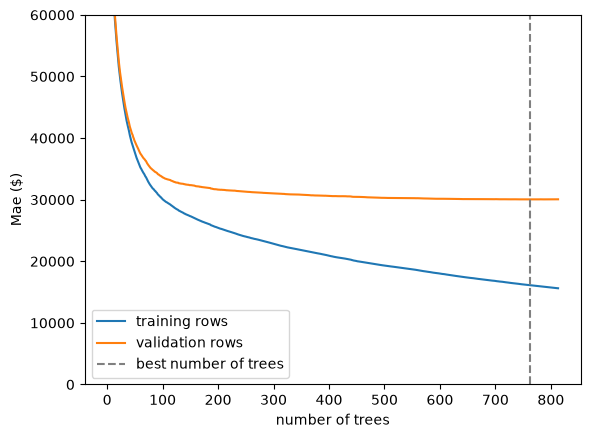

In [4]:
import matplotlib.pyplot as plt

history = model.evals_result()
plt.plot(history["validation_0"]["mae"], label="training rows")
plt.plot(history["validation_1"]["mae"], label="validation rows")
plt.axvline(model.best_iteration, color="gray", linestyle="--", label="best number of trees")
plt.ylim(0, 60_000)
plt.xlabel("number of trees")
plt.ylabel("Mae ($)")
plt.legend()
plt.show()

### Reading the chart

#### Why "validation_0" and "validation_1"?

XGBoost doesn't know what each set is: it names the entries of `eval_set` **by their position in the list**.

```python
eval_set=[(X_train, y_train), (X_validation, y_validation)]
#          position 0 → "validation_0"   position 1 → "validation_1"
```

"Validation" here only means "a set I evaluate on", so even the training rows are called `validation_0`.

**The order matters:** early stopping watches only the **last** set in the list. Here that's the validation rows, which is correct. With the order swapped, it would watch the training error, which keeps going down forever.

#### Why is the training error so much lower?

| Trees | MAE on training rows | MAE on validation rows |
|---|---|---|
| 1 | 87,167 | 88,261 |
| 50 | 37,851 | 39,643 |
| 100 | 30,190 | 33,721 |
| 300 | 22,869 | 31,021 |
| **764** (best) | **16,113** | **30,044** |
| 814 (stopped) | 15,623 | 30,063 |

At first the two curves are almost the same: the model learns real patterns that apply to every house. After about 100 trees they separate:

- **Training rows:** the model is fitted on these exact houses and their answers. Each new tree corrects what's left on them, so the error keeps falling. That includes their noise: it is memorizing them.
- **Validation rows:** the model has never seen them, so memorizing doesn't help. The error flattens around 30,000 and then rises slightly (30,044 → 30,063).

**Training error shows how well it memorized, validation error shows how well it learned.** That's why early stopping watches validation. After the best tree (764) it ran 50 more without improvement (`early_stopping_rounds=50`), stopped at 814, and kept the best one.

The gap between the curves (16k vs 30k) isn't a bug. What matters is the validation curve: once it stops going down, more trees only memorize.

#Testing it once

In [5]:
mean_absolute_error(y_test, model.predict(X_test))

30643.02337977683

About 30643 vs 32400 in the for the forest tested, on the same rows. Some 5% lower with less code, since the model almost needs
no preparation of the data ( only the text column marked as category ), and although it learned from fewer rows, 12384 against 16512
because the last rows are for early stopping

# Two other libraries LightGBM and CatBoost
- LightGBM (Microsoft): Grows each tree leaf by leaf, always spliting the leaf that most reduces de error, its often faster on large tables.
- CatBoost (Yandex): Handles categorical columns with many values particulary well, and its default setting are often good without tunning.

 # Settings
| Setting | Meaning | Usual approach |
| --- | --- | --- |
| n_estimators | maximun number of trees | high, withe early stopping approach |
| learning_rate | how much of each tree is added | 0.01 to 1: smaller needs more trees |
| max_depth | depth of each tree, default 6 | 3 to 10 |
| min_child_weight | minimum sum of each derivatives in a leaf, for the squared error, the minimun number of rows | larger smooths the model |
| sumbsample, colsample_bytree | share of rows, and features each tree sees | below 1 to make trees differ, as the bootstrap samples and the random features of a random forest do |
| reg_lambda, reg_alpha, gamma | the penalties of the objective | raise them when the model overfits |
| eval_metric, early_stopping_rounds | what to watch on eval_set, and how patiently | the measure the problem is judged by | 